# K2-Horizon-7B → tool-use / browser agent (QLoRA on a Colab T4)

Fine-tunes **`IFM/K2-Horizon-7B`** with QLoRA on a single **T4 (16 GB)** so it is sharper at multi-step tool calling — web search, page fetch, and **browser automation (Playwright-style MCP tools)** — when driven by **OpenCode / Harness** through `llama-server`.

**Plug and play:** set a `HF_TOKEN` secret (optional), pick **Runtime ▸ Change runtime type ▸ T4 GPU** (High-RAM if offered), then **Runtime ▸ Run all**. Everything else is automatic, resumable, and time-boxed.

| Stage | What happens | Approx. time on T4 |
|---|---|---|
| Setup | pinned installs, Drive mount, download base (18 GB) | 10–15 min |
| Data | Toucan-1.5M (SFT) → K2 chat template, browser/web-weighted mix, loss masks | 5–10 min |
| Calibrate | measures *your* tokens/s, sizes the dataset to `TRAIN_HOURS` | 3 min |
| Train | QLoRA r=16, all linear layers, checkpoints to Drive every 20 steps | `TRAIN_HOURS` (default 2.5 h) |
| Eval | held-out loss + tool-call accuracy, **base vs tuned** | ~10 min |
| Export | streaming LoRA merge → GGUF via the **K2Horizon llama.cpp fork** → Q4_K_M | 30–45 min |
| Smoke test | CUDA `llama-server --jinja` + a real OpenAI-style tool-call request | ~20 min |

**Why not stock llama.cpp?** `k2_horizon` is not in upstream yet — the GGUF must be produced (and served) with `MBZUAI-IFM/llama.cpp@model/K2Horizon`.

**If the runtime disconnects:** re-run all cells. The data plan, the sample count, and the latest checkpoint are on Drive, so training resumes where it stopped.


## 1 · Config
Everything tunable lives here. Defaults are sized for a T4 and a ~4–5 h total session.

In [1]:
# ============================ CONFIG — edit, then Runtime ▸ Run all ============================
BASE_MODEL         = "IFM/K2-Horizon-7B"
BASE_REVISION      = "main"            # pin a commit hash for reproducibility
DATASET            = "Agent-Ark/Toucan-1.5M"
DATASET_CONFIG     = "SFT"             # curated 119k-row SFT subset, real MCP tool executions (Apache-2.0)
WEB_FRACTION       = 0.60              # share of browser / web-research trajectories in the mix
SYSTEM_PROMPT_PROB = 0.50              # share of samples given a harness-style system prompt
TOOL_RESPONSE_MAX_CHARS = 2000         # truncate long tool outputs (OpenCode/Harness truncate too)
MAX_SEQ_LEN        = 2048              # T4-safe. 3072 works but ~1.6x slower per sample
CANDIDATE_POOL     = 6000              # rows converted + tokenized before selection
EVAL_SIZE          = 40                # held-out samples for eval loss
GEN_EVAL_SAMPLES   = 8                 # held-out samples for tool-call accuracy (base vs tuned); 0 = skip
GEN_EVAL_EFFORT    = "low"             # reasoning_effort for the generation eval (keeps it fast)
EXTRA_JSONL        = ""                # optional: your own Harness/OpenCode traces, one {"messages","tools"} per line
EXTRA_REPEAT       = 3                 # upsample your own traces

TRAIN_HOURS        = 2.5               # training wall-clock budget; sample count is auto-sized to fit
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.0
LORA_TARGETS       = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
LR                 = 1e-4              # conservative: the base is already RL-tuned for tools/search
GRAD_ACCUM         = 8                 # effective batch = 8 sequences
WARMUP_RATIO       = 0.05
SAVE_EVERY_STEPS   = 20
TRAIN_ON_THINK     = False             # Toucan has no reasoning traces -> never train "empty thinking"
TOOL_CALL_FORMAT   = "xml"             # K2 template default; llama-server uses the default too
TOOL_PRESENTATION_FORMAT = "markdown"  # K2 template default
COMPUTE_DTYPE      = "auto"            # auto: fp16 on T4 (no bf16 tensor cores), bf16 on L4/A100
SEED               = 3407

USE_DRIVE          = True              # checkpoints + outputs survive disconnects
DRIVE_DIR          = "/content/drive/MyDrive/k2-horizon-toolft"
HF_PUSH            = True              # needs Colab secret HF_TOKEN with write access
HF_REPO_ID         = ""                # "" -> <your-username>/K2-Horizon-7B-ToolUse
HF_PRIVATE         = True

EXPORT_GGUF        = True
GGUF_QUANTS        = ["Q4_K_M"]        # 11 GB GPU (1080 Ti) -> Q4_K_M; add "Q5_K_M"/"Q8_0" for bigger cards
KEEP_BF16_GGUF     = False
EXPORT_LORA_GGUF   = True              # small adapter GGUF for `llama-server --lora` (best-effort)
LLAMA_CPP_REPOS    = ["https://github.com/MBZUAI-IFM/llama.cpp", "https://github.com/ifm-ai/llama.cpp"]
LLAMA_CPP_BRANCH   = "model/K2Horizon"
RUN_SERVER_SMOKE_TEST = True           # builds CUDA llama-server and checks a real tool call
SERVED_MODEL_NAME  = "k2-horizon-7b-tooluse"
RUN_NAME           = "k2h7b-tooluse-v1"


## 2 · Runtime check + installs
Only the training stack is installed/upgraded; Colab's `torch` is left alone (upgrading it breaks the CUDA build of bitsandbytes).

In [2]:
import os, sys, subprocess, shutil, time, json, gc, re, random
from pathlib import Path

if "transformers" in sys.modules:
    print("⚠️ transformers was already imported in this session. If the install below upgrades it, "
          "use Runtime ▸ Restart session, then Run all again.")

def sh(cmd, check=True, cwd=None, env=None):
    """Run a shell command, stream its output, raise on failure."""
    print(f"$ {cmd}")
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env=env, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, bufsize=1)
    lines = []
    for line in p.stdout:
        print(line, end="")
        lines.append(line)
    p.wait()
    if check and p.returncode != 0:
        raise RuntimeError(f"command failed ({p.returncode}): {cmd}\n" + "".join(lines[-30:]))
    return "".join(lines)

gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader",
                     shell=True, capture_output=True, text=True).stdout.strip()
if not gpu:
    raise SystemExit("No GPU. Runtime ▸ Change runtime type ▸ T4 GPU, then Run all.")
print("GPU:", gpu)
ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
print(f"RAM: {ram_gb:.1f} GB | free disk: {shutil.disk_usage('/').free / 1e9:.0f} GB")

%pip install -q -U "transformers>=5.15,<6" "peft>=0.18" "bitsandbytes>=0.48" "accelerate>=1.10" "datasets>=3.0" "huggingface_hub>=1.0" safetensors sentencepiece protobuf

import torch, transformers, peft, bitsandbytes, accelerate, datasets, huggingface_hub
from packaging.version import Version
print({m.__name__: m.__version__ for m in (torch, transformers, peft, bitsandbytes, accelerate, datasets, huggingface_hub)})
assert Version(transformers.__version__) >= Version("5.15"), \
    "K2-Horizon's remote code needs transformers>=5.15 — Runtime ▸ Restart session, then Run all."
CC = torch.cuda.get_device_capability(0)
print("compute capability:", CC)


GPU: Tesla T4, 15360 MiB
RAM: 13.6 GB | free disk: 75 GB
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 101.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 42.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 62.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 33.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
grpcio-st

## 3 · Helper module
`k2ft.py` holds all model/data logic (conversion, loss masks, chunked loss, training loop, streaming merge, tool-call parser). It is unit-tested separately; it's written to disk here so the notebook is self-contained.

In [3]:
%%writefile k2ft.py
"""k2ft — QLoRA tool-use fine-tuning helpers for IFM/K2-Horizon-7B on a Colab T4.

Everything model/data-specific lives here so the notebook stays thin and this
file can be unit-tested off-GPU (see tests/test_k2ft.py).

Sections
  1. Toucan-1.5M (SFT subset) -> K2-Horizon chat-template messages
  2. Tokenisation + loss masks (assistant turns only, reasoning optional)
  3. Memory-lean loss (chunked cross-entropy, never materialises B*T*250k logits)
  4. Training loop (fp16/bf16 autocast, token-weighted grad-accum, resumable)
  5. Time-budget planning
  6. Streaming LoRA merge into the bf16 safetensors shards (CPU, ~1 shard of RAM)
  7. Tool-call parsing + scoring for quick evals
"""

from __future__ import annotations

import ast
import json
import math
import os
import random
import re
import shutil
import time
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Callable, Iterable

import torch
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

# --------------------------------------------------------------------------- #
# 1. Dataset conversion
# --------------------------------------------------------------------------- #

# Matched against tool names/descriptions + Toucan's target_tools column to
# up-weight browser / web-research trajectories.
WEB_KEYWORDS = (
    "browser", "browse", "playwright", "puppeteer", "selenium", "navigate",
    "click", "screenshot", "scrape", "crawl", "fetch", "url", "web_search",
    "websearch", "search_web", "web-search", "exa", "tavily", "firecrawl",
    "brave", "duckduckgo", "serp", "google_search", "http_get", "webpage",
)
_WEB_RE = re.compile("|".join(re.escape(k) for k in WEB_KEYWORDS), re.I)

# Generic agent-harness system prompts. Injected into a fraction of samples so
# the adapter stays robust to the long system prompts OpenCode / Harness send.
AGENT_SYSTEM_PROMPTS = (
    "You are an autonomous coding and research agent running inside a terminal "
    "harness. Use the provided tools to gather facts before answering. Call "
    "tools only with arguments that match their schemas.",
    "You are a helpful assistant with access to tools, including a web browser. "
    "Prefer tool calls over guessing when the user asks about live or external "
    "information. Summarise tool results concisely for the user.",
    "You are an AI agent connected to MCP servers. Think about which tool fits "
    "the task, call it, read the result, and continue until the task is done.",
    "You are a software engineering assistant. You can read files, run "
    "commands, and browse the web through tools. Be precise and terse.",
)


def is_web_text(text: str) -> bool:
    """True if the text mentions browser / web-research tooling."""
    return bool(_WEB_RE.search(text or ""))


def sanitize_schema(spec: Any) -> Any:
    """Make a JSON-schema acceptable to K2-Horizon's strict chat template.

    The template raises if `required` is not a list, names a property that is
    not defined, or appears without `properties`. Toucan has a few such schemas.
    """
    if isinstance(spec, list):
        return [sanitize_schema(s) for s in spec]
    if not isinstance(spec, dict):
        return spec
    out = {k: sanitize_schema(v) for k, v in spec.items()}
    props = out.get("properties")
    if "required" in out:
        req = out["required"]
        if not isinstance(req, list) or not isinstance(props, dict) or not props:
            out.pop("required")
        else:
            kept = [r for r in req if isinstance(r, str) and r in props]
            if kept:
                out["required"] = kept
            else:
                out.pop("required")
    return out


def normalize_tools(tools: Any) -> list[dict] | None:
    """OpenAI-style tool list -> list with dict `parameters` (template requires)."""
    if isinstance(tools, str):
        try:
            tools = json.loads(tools)
        except json.JSONDecodeError:
            return None
    if not isinstance(tools, list):
        return None
    out = []
    for t in tools:
        if not isinstance(t, dict):
            return None
        fn = t.get("function", t)
        if not isinstance(fn, dict) or not fn.get("name"):
            return None
        params = fn.get("parameters")
        if isinstance(params, str):
            try:
                params = json.loads(params)
            except json.JSONDecodeError:
                return None
        if not isinstance(params, dict):
            params = {"type": "object", "properties": {}}
        params = sanitize_schema(params)
        new_fn = {"name": fn["name"], "description": fn.get("description") or "", "parameters": params}
        out.append({"type": "function", "function": new_fn})
    return out


def parse_toucan_tool_call(content: str) -> dict | None:
    """Toucan SFT stores calls as a python-repr dict: {'name': .., 'arguments': '<json>'}."""
    obj: Any = None
    try:
        obj = ast.literal_eval(content)
    except (ValueError, SyntaxError):
        try:
            obj = json.loads(content)
        except json.JSONDecodeError:
            return None
    if not isinstance(obj, dict) or not isinstance(obj.get("name"), str):
        return None
    args = obj.get("arguments", {})
    if isinstance(args, str):
        args = args.strip()
        if not args:
            args = {}
        else:
            try:
                args = json.loads(args)
            except json.JSONDecodeError:
                return None
    if args is None:
        args = {}
    if not isinstance(args, dict):
        return None
    args = {k: v for k, v in args.items() if isinstance(k, str) and k != ""}
    return {"type": "function", "function": {"name": obj["name"], "arguments": args}}


def _truncate(text: str, max_chars: int) -> str:
    if max_chars <= 0 or len(text) <= max_chars:
        return text
    head = max_chars * 3 // 4
    tail = max_chars - head
    return f"{text[:head]}\n...[truncated {len(text) - max_chars} chars]...\n{text[-tail:]}"


def toucan_to_messages(
    raw_messages: Any,
    tool_response_max_chars: int = 2000,
) -> list[dict] | None:
    """Convert Toucan SFT roles (user/assistant/tool_call/tool_response) to
    K2-Horizon template messages (user/assistant[+tool_calls]/tool).

    Every assistant message gets `reasoning_content` because the K2 template
    raises when an assistant turn has no thinking field.
    """
    if isinstance(raw_messages, str):
        try:
            raw_messages = json.loads(raw_messages)
        except json.JSONDecodeError:
            return None
    if not isinstance(raw_messages, list):
        return None

    out: list[dict] = []
    pending: dict | None = None

    def flush() -> None:
        nonlocal pending
        if pending is not None:
            out.append(pending)
            pending = None

    for m in raw_messages:
        if not isinstance(m, dict):
            return None
        role = m.get("role")
        content = m.get("content")
        content = "" if content is None else str(content)
        if role == "system":
            flush()
            if out:  # mid-conversation system messages are not useful here
                continue
            out.append({"role": "system", "content": content})
        elif role == "user":
            flush()
            out.append({"role": "user", "content": content})
        elif role == "assistant":
            flush()
            pending = {"role": "assistant", "content": content, "reasoning_content": ""}
        elif role in ("tool_call", "function_call"):
            call = parse_toucan_tool_call(content)
            if call is None:
                return None
            if pending is None:
                pending = {"role": "assistant", "content": "", "reasoning_content": ""}
            pending.setdefault("tool_calls", []).append(call)
        elif role in ("tool_response", "tool", "function", "observation"):
            flush()
            out.append({"role": "tool", "content": _truncate(content, tool_response_max_chars)})
        else:
            return None
    flush()

    roles = [m["role"] for m in out]
    if "user" not in roles or not out or out[-1]["role"] != "assistant":
        return None
    # each tool message must follow an assistant tool call (directly or another tool msg)
    prev = None
    for m in out:
        if m["role"] == "tool" and prev not in ("tool", "assistant_call"):
            return None
        prev = "assistant_call" if (m["role"] == "assistant" and m.get("tool_calls")) else m["role"]
    return out


def openai_to_messages(messages: list[dict]) -> list[dict] | None:
    """Normalise OpenAI chat-format messages (e.g. exported Harness sessions)."""
    out = []
    for m in messages:
        m = dict(m)
        role = m.get("role")
        if role == "assistant":
            if not isinstance(m.get("reasoning_content"), str):
                m["reasoning_content"] = m.pop("reasoning", "") or ""
            if m.get("content") is None:
                m["content"] = ""
            calls = []
            for c in m.get("tool_calls") or []:
                fn = dict(c.get("function", c))
                args = fn.get("arguments", {})
                if isinstance(args, str):
                    try:
                        args = json.loads(args) if args.strip() else {}
                    except json.JSONDecodeError:
                        return None
                if not isinstance(args, dict):
                    return None
                calls.append({"type": "function", "function": {"name": fn["name"], "arguments": args}})
            if calls:
                m["tool_calls"] = calls
            else:
                m.pop("tool_calls", None)
            m.pop("tool_call_id", None)
        elif role == "tool":
            m = {"role": "tool", "content": m.get("content") if isinstance(m.get("content"), str) else json.dumps(m.get("content"))}
        elif role in ("user", "system"):
            m = {"role": role, "content": m.get("content") or ""}
        else:
            return None
        out.append(m)
    if not out or out[-1]["role"] != "assistant":
        return None
    return out


def toucan_row_to_example(
    row: dict,
    tool_response_max_chars: int = 2000,
    system_prompt: str | None = None,
) -> dict | None:
    """One Toucan SFT row -> {'messages', 'tools', 'is_web', 'subset'} or None."""
    tools = normalize_tools(row.get("tools"))
    if tools is None:
        return None
    msgs = toucan_to_messages(row.get("messages"), tool_response_max_chars)
    if msgs is None:
        return None
    if system_prompt and msgs[0]["role"] != "system":
        msgs = [{"role": "system", "content": system_prompt}] + msgs
    probe = " ".join(
        [str(row.get("target_tools", ""))]
        + [t["function"]["name"] + " " + t["function"]["description"][:200] for t in tools]
    )
    return {
        "messages": msgs,
        "tools": tools,
        "is_web": is_web_text(probe),
        "subset": row.get("subset_name", ""),
    }


def select_mixture(
    examples: list[dict],
    n_total: int,
    web_fraction: float,
    rng: random.Random,
) -> list[dict]:
    """Pick n_total examples with ~web_fraction browser/web trajectories."""
    web = [e for e in examples if e.get("is_web")]
    other = [e for e in examples if not e.get("is_web")]
    rng.shuffle(web)
    rng.shuffle(other)
    n_web = min(len(web), round(n_total * web_fraction))
    n_other = min(len(other), n_total - n_web)
    n_web = min(len(web), n_total - n_other)  # backfill if 'other' ran short
    picked = web[:n_web] + other[:n_other]
    rng.shuffle(picked)
    return picked


# --------------------------------------------------------------------------- #
# 2. Tokenisation + masks
# --------------------------------------------------------------------------- #

_ASSISTANT_RE = re.compile(r"<\|ifm\|im_start\|>assistant\n?(.*?<\|ifm\|im_end\|>)", re.S)
_THINK_RE = re.compile(r"<(ifm\|think(?:_fast|_faster)?)>.*?</\1>", re.S)


def trainable_char_spans(text: str, train_on_think: bool = False) -> list[tuple[int, int]]:
    """Character spans that receive loss: assistant turn bodies up to and
    including <|ifm|im_end|>. If train_on_think is False the reasoning block is
    excluded (it stays in the input as context). Toucan has no reasoning traces,
    so training on its empty <ifm|think></ifm|think> would teach the model to
    skip thinking — masking avoids that."""
    spans: list[tuple[int, int]] = []
    for m in _ASSISTANT_RE.finditer(text):
        s, e = m.start(1), m.end(1)
        if train_on_think:
            spans.append((s, e))
            continue
        cur = s
        for t in _THINK_RE.finditer(text, s, e):
            if t.start() > cur:
                spans.append((cur, t.start()))
            cur = max(cur, t.end())
        if cur < e:
            spans.append((cur, e))
    return spans


def labels_from_offsets(
    input_ids: list[int],
    offsets: list[tuple[int, int]],
    spans: list[tuple[int, int]],
) -> list[int]:
    """Token gets its id as label if its first char lies inside a span."""
    labels = [-100] * len(input_ids)
    if not spans:
        return labels
    j = 0
    for i, (a, b) in enumerate(offsets):
        if b <= a:
            continue
        while j < len(spans) and spans[j][1] <= a:
            j += 1
        if j == len(spans):
            break
        s, e = spans[j]
        if s <= a < e:
            labels[i] = input_ids[i]
    return labels


def render_example(tokenizer, ex: dict, chat_kwargs: dict | None = None) -> str:
    return tokenizer.apply_chat_template(
        ex["messages"],
        tools=ex.get("tools") or None,
        tokenize=False,
        add_generation_prompt=False,
        **(chat_kwargs or {}),
    )


def tokenize_example(
    tokenizer,
    ex: dict,
    max_len: int,
    chat_kwargs: dict | None = None,
    train_on_think: bool = False,
) -> dict | None:
    """Render with the model's own chat template, tokenize, build labels.
    Returns None if the template rejects the sample or it exceeds max_len."""
    try:
        text = render_example(tokenizer, ex, chat_kwargs)
    except Exception:  # template raise_exception() on malformed sample
        return None
    enc = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    ids = list(enc["input_ids"])
    if len(ids) > max_len:
        return None
    labels = labels_from_offsets(ids, list(enc["offset_mapping"]), trainable_char_spans(text, train_on_think))
    n_train = sum(1 for x in labels if x != -100)
    if n_train == 0:
        return None
    return {"input_ids": ids, "labels": labels, "n_tokens": len(ids), "n_train": n_train}


def collate(batch: list[dict], pad_id: int) -> dict[str, torch.Tensor]:
    """Right-pad to the longest sample in the micro-batch."""
    n = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), n), pad_id, dtype=torch.long)
    labels = torch.full((len(batch), n), -100, dtype=torch.long)
    attn = torch.zeros((len(batch), n), dtype=torch.long)
    for i, b in enumerate(batch):
        k = len(b["input_ids"])
        ids[i, :k] = torch.tensor(b["input_ids"])
        labels[i, :k] = torch.tensor(b["labels"])
        attn[i, :k] = 1
    return {"input_ids": ids, "labels": labels, "attention_mask": attn}


# --------------------------------------------------------------------------- #
# 3. Loss
# --------------------------------------------------------------------------- #

def _ce_sum(h: torch.Tensor, y: torch.Tensor, lm_head: torch.nn.Module) -> torch.Tensor:
    logits = lm_head(h).float()
    return F.cross_entropy(logits, y, reduction="sum")


def chunked_lm_loss_sum(
    hidden: torch.Tensor,
    labels: torch.Tensor,
    lm_head: torch.nn.Module,
    chunk_size: int = 256,
) -> tuple[torch.Tensor, int]:
    """Sum of next-token CE over labelled positions + their count.

    Only labelled positions go through lm_head, in checkpointed chunks, so the
    250k-vocab logits never exist for the whole sequence at once.
    """
    h = hidden[:, :-1, :]
    y = labels[:, 1:].to(hidden.device)
    mask = y != -100
    h = h[mask]
    y = y[mask]
    n = int(y.numel())
    if n == 0:
        return hidden.sum() * 0.0, 0
    total = torch.zeros((), dtype=torch.float32, device=hidden.device)
    for i in range(0, n, chunk_size):
        hs, ys = h[i:i + chunk_size], y[i:i + chunk_size]
        if torch.is_grad_enabled() and hs.requires_grad:
            total = total + checkpoint(_ce_sum, hs, ys, lm_head, use_reentrant=False)
        else:
            total = total + _ce_sum(hs, ys, lm_head)
    return total, n


def backbone_and_head(model) -> tuple[torch.nn.Module, torch.nn.Module]:
    """(decoder stack, lm_head) for a plain or PEFT-wrapped CausalLM."""
    m = model.get_base_model() if hasattr(model, "get_base_model") else model
    return m.model, m.lm_head


def forward_loss_sum(model, batch: dict, chunk_size: int = 256) -> tuple[torch.Tensor, int]:
    backbone, head = backbone_and_head(model)
    dev = next(p for p in head.parameters()).device
    out = backbone(
        input_ids=batch["input_ids"].to(dev),
        attention_mask=batch["attention_mask"].to(dev),
        use_cache=False,
    )
    hidden = out.last_hidden_state if hasattr(out, "last_hidden_state") else out[0]
    return chunked_lm_loss_sum(hidden, batch["labels"], head, chunk_size)


@torch.no_grad()
def evaluate_loss(model, samples: list[dict], pad_id: int, dtype: torch.dtype, chunk_size: int = 256) -> float:
    model.eval()
    tot, cnt = 0.0, 0
    dev_type = "cuda" if torch.cuda.is_available() else "cpu"
    for s in samples:
        with torch.autocast(dev_type, dtype=dtype, enabled=dev_type == "cuda"):
            ls, n = forward_loss_sum(model, collate([s], pad_id), chunk_size)
        tot += float(ls)
        cnt += n
    return tot / max(cnt, 1)


# --------------------------------------------------------------------------- #
# 4. Training loop
# --------------------------------------------------------------------------- #

@dataclass
class TrainConfig:
    lr: float = 1e-4
    weight_decay: float = 0.0
    warmup_ratio: float = 0.05
    grad_accum: int = 8
    max_grad_norm: float = 1.0
    save_every: int = 25
    log_every: int = 5
    chunk_size: int = 256
    time_budget_s: float | None = None  # hard stop safety net
    seed: int = 3407


@dataclass
class TrainState:
    step: int = 0
    total_steps: int = 0
    history: list[dict] = field(default_factory=list)


def cosine_lr(step: int, total: int, warmup: int) -> float:
    if total <= 0:
        return 1.0
    if step < warmup:
        return (step + 1) / max(1, warmup)
    prog = (step - warmup) / max(1, total - warmup)
    return 0.5 * (1.0 + math.cos(math.pi * min(1.0, prog)))


def trainable_state_dict(model) -> dict[str, torch.Tensor]:
    return {k: v.detach().cpu() for k, v in model.named_parameters() if v.requires_grad}


def save_checkpoint(path: str | Path, model, opt, scaler, state: TrainState) -> None:
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    tmp.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            "params": trainable_state_dict(model),
            "opt": opt.state_dict(),
            "scaler": scaler.state_dict() if scaler is not None else None,
            "step": state.step,
            "total_steps": state.total_steps,
            "history": state.history,
        },
        tmp / "train_state.pt",
    )
    if path.exists():
        shutil.rmtree(path)
    tmp.rename(path)  # atomic-ish: a crash mid-save never corrupts the last good ckpt


def load_checkpoint(path: str | Path, model, opt, scaler) -> TrainState:
    blob = torch.load(Path(path) / "train_state.pt", map_location="cpu", weights_only=False)
    named = dict(model.named_parameters())
    for k, v in blob["params"].items():
        named[k].data.copy_(v.to(named[k].device, named[k].dtype))
    opt.load_state_dict(blob["opt"])
    if scaler is not None and blob.get("scaler"):
        scaler.load_state_dict(blob["scaler"])
    return TrainState(step=blob["step"], total_steps=blob["total_steps"], history=blob.get("history", []))


def latest_checkpoint(ckpt_dir: str | Path) -> Path | None:
    d = Path(ckpt_dir)
    if not d.exists():
        return None
    c = sorted(
        (p for p in d.glob("step_*") if (p / "train_state.pt").exists()),
        key=lambda p: int(p.name.split("_")[1]),
    )
    return c[-1] if c else None


def train(
    model,
    samples: list[dict],
    pad_id: int,
    cfg: TrainConfig,
    dtype: torch.dtype,
    ckpt_dir: str | Path,
    log: Callable[[str], None] = print,
) -> TrainState:
    """One epoch over `samples` (micro-batch 1), token-weighted grad accumulation,
    cosine LR, periodic resumable checkpoints. Returns the final TrainState."""
    dev_type = "cuda" if torch.cuda.is_available() else "cpu"
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=cfg.lr, weight_decay=cfg.weight_decay, betas=(0.9, 0.999))
    use_scaler = dev_type == "cuda" and dtype == torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler) if dev_type == "cuda" else None

    total_steps = math.ceil(len(samples) / cfg.grad_accum)
    warmup = max(1, round(total_steps * cfg.warmup_ratio))
    state = TrainState(total_steps=total_steps)

    last = latest_checkpoint(ckpt_dir)
    if last is not None:
        state = load_checkpoint(last, model, opt, scaler)
        if state.total_steps != total_steps:
            log(f"[resume] checkpoint planned {state.total_steps} steps, now {total_steps}; continuing schedule with new total")
            state.total_steps = total_steps
        log(f"[resume] from {last} at step {state.step}/{total_steps}")

    model.train()
    t0 = time.time()
    tok_seen = 0
    start_step = state.step
    for step in range(state.step, total_steps):
        group = samples[step * cfg.grad_accum:(step + 1) * cfg.grad_accum]
        n_tok = sum(s["n_train"] for s in group)
        lr = cfg.lr * cosine_lr(step, total_steps, warmup)
        for g in opt.param_groups:
            g["lr"] = lr
        loss_acc = 0.0
        for s in group:
            batch = collate([s], pad_id)
            with torch.autocast(dev_type, dtype=dtype, enabled=dev_type == "cuda"):
                lsum, _ = forward_loss_sum(model, batch, cfg.chunk_size)
            loss = lsum / n_tok
            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"non-finite loss at step {step}; with fp16 this usually means activation "
                    "overflow — set COMPUTE_DTYPE='bfloat16' in the config cell and rerun."
                )
            if scaler is not None and use_scaler:
                scaler.scale(loss).backward()
            else:
                loss.backward()
            loss_acc += float(loss.detach())
            tok_seen += s["n_tokens"]
        if scaler is not None and use_scaler:
            scaler.unscale_(opt)
        gnorm = float(torch.nn.utils.clip_grad_norm_(params, cfg.max_grad_norm))
        if scaler is not None and use_scaler:
            scaler.step(opt)
            scaler.update()
        else:
            opt.step()
        opt.zero_grad(set_to_none=True)
        state.step = step + 1
        state.history.append({"step": state.step, "loss": loss_acc, "lr": lr, "grad_norm": gnorm})

        elapsed = time.time() - t0
        if state.step % cfg.log_every == 0 or state.step == total_steps:
            per_step = elapsed / max(1, state.step - start_step)
            eta = per_step * (total_steps - state.step)
            log(
                f"step {state.step:>4}/{total_steps} | loss {loss_acc:.4f} | lr {lr:.2e} | "
                f"gnorm {gnorm:.2f} | {tok_seen / max(elapsed, 1e-6):.0f} tok/s | "
                f"ETA {eta / 60:.1f} min"
            )
        if state.step % cfg.save_every == 0 or state.step == total_steps:
            save_checkpoint(Path(ckpt_dir) / f"step_{state.step:05d}", model, opt, scaler, state)
        if cfg.time_budget_s is not None and elapsed > cfg.time_budget_s and state.step < total_steps:
            log(f"[time-guard] budget {cfg.time_budget_s / 3600:.2f} h exceeded; stopping at step {state.step}")
            save_checkpoint(Path(ckpt_dir) / f"step_{state.step:05d}", model, opt, scaler, state)
            break
    return state


# --------------------------------------------------------------------------- #
# 5. Time budget
# --------------------------------------------------------------------------- #

def plan_sample_count(token_lengths: Iterable[int], tokens_per_sec: float, budget_s: float, safety: float = 0.9) -> int:
    """How many samples (in the given order) fit in budget_s at the measured speed."""
    if tokens_per_sec <= 0:
        return 0
    limit = budget_s * safety * tokens_per_sec
    acc, n = 0, 0
    for t in token_lengths:
        if acc + t > limit:
            break
        acc += t
        n += 1
    return n


# --------------------------------------------------------------------------- #
# 6. Streaming LoRA merge (CPU)
# --------------------------------------------------------------------------- #

_LORA_KEY_RE = re.compile(r"^(?:base_model\.model\.)?(.+)\.lora_([AB])(?:\.default)?\.weight$")


def read_lora_scales(adapter_dir: str | Path) -> tuple[dict, float]:
    cfg = json.loads((Path(adapter_dir) / "adapter_config.json").read_text())
    if cfg.get("use_dora"):
        raise NotImplementedError("DoRA adapters are not supported by the streaming merge")
    if cfg.get("rank_pattern") or cfg.get("alpha_pattern"):
        raise NotImplementedError("rank_pattern/alpha_pattern not supported by the streaming merge")
    if cfg.get("fan_in_fan_out"):
        raise NotImplementedError("fan_in_fan_out adapters not supported")
    r, alpha = cfg["r"], cfg["lora_alpha"]
    scale = alpha / math.sqrt(r) if cfg.get("use_rslora") else alpha / r
    return cfg, scale


def load_lora_pairs(adapter_dir: str | Path) -> dict[str, dict[str, torch.Tensor]]:
    """{'model.layers.0.self_attn.q_proj': {'A': tensor, 'B': tensor}, ...}"""
    from safetensors.torch import load_file

    sd = load_file(str(Path(adapter_dir) / "adapter_model.safetensors"))
    pairs: dict[str, dict[str, torch.Tensor]] = {}
    for k, v in sd.items():
        m = _LORA_KEY_RE.match(k)
        if not m:
            raise ValueError(f"unexpected non-LoRA tensor in adapter: {k} (modules_to_save is not supported)")
        pairs.setdefault(m.group(1), {})[m.group(2)] = v
    bad = [k for k, v in pairs.items() if set(v) != {"A", "B"}]
    if bad:
        raise ValueError(f"incomplete LoRA pairs: {bad[:5]}")
    return pairs


def merge_lora_streaming(
    base_dir: str | Path,
    adapter_dir: str | Path,
    out_dir: str | Path,
    log: Callable[[str], None] = print,
) -> dict:
    """Merge W' = W + scale * B @ A shard-by-shard into a copy of base_dir.

    Peak RAM ~= the largest shard (K2-Horizon-7B: ~4.5 GB), so it fits on a
    standard 12.7 GB Colab runtime where a full bf16 load (18 GB) would not.
    """
    from safetensors import safe_open
    from safetensors.torch import save_file

    base_dir, out_dir = Path(base_dir), Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    _, scale = read_lora_scales(adapter_dir)
    pairs = load_lora_pairs(adapter_dir)
    remaining = set(pairs)

    shards = sorted(p for p in base_dir.glob("*.safetensors"))
    if not shards:
        raise FileNotFoundError(f"no .safetensors in {base_dir}")
    for f in base_dir.iterdir():
        if f.is_file() and f.suffix != ".safetensors":
            shutil.copy2(f, out_dir / f.name)

    merged = 0
    for shard in shards:
        tensors: dict[str, torch.Tensor] = {}
        with safe_open(str(shard), framework="pt") as fh:
            meta = fh.metadata() or {}
            for key in fh.keys():
                t = fh.get_tensor(key)
                mod = key[: -len(".weight")] if key.endswith(".weight") else None
                if mod in pairs:
                    a = pairs[mod]["A"].float()
                    b = pairs[mod]["B"].float()
                    delta = (b @ a) * scale
                    if delta.shape != t.shape:
                        raise ValueError(f"shape mismatch for {key}: base {tuple(t.shape)} vs delta {tuple(delta.shape)}")
                    t = (t.float() + delta).to(t.dtype)
                    remaining.discard(mod)
                    merged += 1
                tensors[key] = t.contiguous()
        meta = {**meta, "format": meta.get("format", "pt")}
        save_file(tensors, str(out_dir / shard.name), metadata=meta)
        del tensors
        log(f"[merge] {shard.name}: done ({merged} modules merged so far)")
    if remaining:
        raise RuntimeError(f"{len(remaining)} LoRA modules had no base weight, e.g. {sorted(remaining)[:3]}")
    return {"merged_modules": merged, "scale": scale, "shards": len(shards)}


# --------------------------------------------------------------------------- #
# 7. Tool-call parsing / scoring
# --------------------------------------------------------------------------- #

_CALLS_RE = re.compile(r"<ifm\|tool_calls>(.*?)(?:</ifm\|tool_calls>|$)", re.S)
_CALL_RE = re.compile(r"<ifm\|tool_call>(.*?)</ifm\|tool_call>", re.S)
_ARG_RE = re.compile(
    r"<ifm\|arg_key>(.*?)</ifm\|arg_key>\s*(?:<ifm\|arg_type>.*?</ifm\|arg_type>\s*)?<ifm\|arg_value>(.*?)</ifm\|arg_value>",
    re.S,
)


def _coerce(v: str) -> Any:
    try:
        return json.loads(v)
    except (json.JSONDecodeError, TypeError):
        return v


def parse_tool_calls(text: str) -> list[dict]:
    """Parse K2-Horizon tool calls (xml, xml_typed or json format) from raw text."""
    calls: list[dict] = []
    for block in _CALLS_RE.findall(text or ""):
        for body in _CALL_RE.findall(block):
            body = body.strip()
            if body.startswith("{"):
                try:
                    obj = json.loads(body)
                    calls.append({"name": obj.get("name"), "arguments": obj.get("arguments") or {}})
                except json.JSONDecodeError:
                    continue
                continue
            name = body.split("\n", 1)[0].split("<", 1)[0].strip()
            args = {k.strip(): _coerce(v) for k, v in _ARG_RE.findall(body)}
            calls.append({"name": name, "arguments": args})
    return calls


def score_first_call(pred: list[dict], gold: list[dict]) -> dict:
    """Name match / argument-key match / exact match for the first call."""
    if not gold:
        ok = not pred
        return {"name": ok, "keys": ok, "exact": ok}
    if not pred:
        return {"name": False, "keys": False, "exact": False}
    p, g = pred[0], gold[0]
    name = p.get("name") == g.get("name")
    pa, ga = p.get("arguments") or {}, g.get("arguments") or {}
    keys = name and set(pa) == set(ga)
    exact = keys and all(str(pa[k]).strip() == str(ga[k]).strip() for k in ga)
    return {"name": name, "keys": keys, "exact": exact}


def first_assistant_call_prefix(ex: dict) -> tuple[list[dict], list[dict]] | None:
    """Split an example at its first assistant tool call: (context msgs, gold calls)."""
    for i, m in enumerate(ex["messages"]):
        if m["role"] == "assistant" and m.get("tool_calls"):
            gold = [{"name": c["function"]["name"], "arguments": c["function"]["arguments"]} for c in m["tool_calls"]]
            return ex["messages"][:i], gold
    return None


def human_bytes(n: float) -> str:
    for unit in ("B", "KB", "MB", "GB", "TB"):
        if abs(n) < 1024:
            return f"{n:.1f} {unit}"
        n /= 1024
    return f"{n:.1f} PB"


def free_disk(path: str = "/") -> int:
    return shutil.disk_usage(path).free


def env_flag(name: str, default: bool) -> bool:
    v = os.environ.get(name)
    return default if v is None else v.lower() in ("1", "true", "yes")


Writing k2ft.py


## 4 · Auth, Drive, paths

In [4]:
import importlib
import k2ft
importlib.reload(k2ft)

HF_TOKEN = os.environ.get("HF_TOKEN")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata
    try:
        HF_TOKEN = HF_TOKEN or userdata.get("HF_TOKEN")
    except Exception:
        pass
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    print("HF token: found")
else:
    print("HF token: none (fine for training; HF upload will be skipped). Add one under 🔑 Secrets as HF_TOKEN.")

if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RUN_DIR = Path(DRIVE_DIR) / RUN_NAME
else:
    RUN_DIR = Path("/content/k2ft") / RUN_NAME
WORK = Path("/content/work")                # big scratch files stay on local disk
CKPT_DIR = RUN_DIR / "checkpoints"
ADAPTER_DIR = RUN_DIR / "adapter"
PLAN_PATH = RUN_DIR / "plan.pt"
REPORT_PATH = RUN_DIR / "report.json"
for d in (RUN_DIR, WORK, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)
random.seed(SEED)
torch.manual_seed(SEED)
REPORT = json.loads(REPORT_PATH.read_text()) if REPORT_PATH.exists() else {}
def save_report():
    REPORT_PATH.write_text(json.dumps(REPORT, indent=2))
print("run dir:", RUN_DIR)


HF token: none (fine for training; HF upload will be skipped). Add one under 🔑 Secrets as HF_TOKEN.
Mounted at /content/drive
run dir: /content/drive/MyDrive/k2-horizon-toolft/k2h7b-tooluse-v1


## 5 · Base model + tokenizer
Downloaded once to the local HF cache (~18 GB). The same files are reused later for the bf16 merge, so nothing is fetched twice.

In [5]:
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer

BASE_DIR = snapshot_download(BASE_MODEL, revision=BASE_REVISION, token=HF_TOKEN)
print("base snapshot:", BASE_DIR, "| free disk:", k2ft.human_bytes(k2ft.free_disk()))
tokenizer = AutoTokenizer.from_pretrained(BASE_DIR, trust_remote_code=True)
PAD_ID = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
CHAT_KWARGS = {"tool_call_format": TOOL_CALL_FORMAT, "tool_presentation_format": TOOL_PRESENTATION_FORMAT}

# --- verify the REAL template behaves the way the masking code assumes -------------------------
_probe = {"messages": [{"role": "user", "content": "open example.com"},
                       {"role": "assistant", "content": "", "reasoning_content": "",
                        "tool_calls": [{"type": "function", "function": {"name": "browser_navigate",
                                                                         "arguments": {"url": "https://example.com"}}}]},
                       {"role": "tool", "content": "Title: Example Domain"},
                       {"role": "assistant", "content": "It says Example Domain.", "reasoning_content": ""}],
          "tools": [{"type": "function", "function": {"name": "browser_navigate", "description": "Navigate to a URL",
                     "parameters": {"type": "object", "properties": {"url": {"type": "string"}}, "required": ["url"]}}}]}
_txt = k2ft.render_example(tokenizer, _probe, CHAT_KWARGS)
_gen = tokenizer.apply_chat_template(_probe["messages"][:1], tools=_probe["tools"], tokenize=False,
                                     add_generation_prompt=True, **CHAT_KWARGS)
assert "<|ifm|im_start|>assistant" in _txt and "<|ifm|im_end|>" in _txt, "unexpected chat format"
assert _gen.rstrip().endswith("<ifm|think>"), f"unexpected generation prompt tail: {_gen[-80:]!r}"
# (the system prompt contains an example <ifm|tool_call>$FUNCTION_NAME block, so parse after the first assistant header)
assert k2ft.parse_tool_calls(_txt.split("<|ifm|im_start|>assistant", 1)[1])[0] == \
    {"name": "browser_navigate", "arguments": {"url": "https://example.com"}}
_alt = k2ft.render_example(tokenizer, _probe, {**CHAT_KWARGS, "tool_call_format": "json"})
assert '<ifm|tool_call>{"name"' in _alt, "chat-template kwargs are not reaching the template (transformers API change?)"
_tok = k2ft.tokenize_example(tokenizer, _probe, 4096, CHAT_KWARGS, TRAIN_ON_THINK)
_trained = tokenizer.decode([i for i, lab in zip(_tok["input_ids"], _tok["labels"]) if lab != -100], skip_special_tokens=False)
assert "<|ifm|im_start|>" not in _trained and "Title: Example Domain" not in _trained
assert _trained.count("<|ifm|im_end|>") == 2 and ("<ifm|think>" not in _trained or TRAIN_ON_THINK)
print("✅ template probe OK. Tokens that receive loss:\n", _trained)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 52 files:   0%|          | 0/52 [00:00<?, ?it/s]

base snapshot: /root/.cache/huggingface/hub/models--IFM--K2-Horizon-7B/snapshots/3b6ae394c1b863c27a306d168b25555837955192 | free disk: 53.1 GB
✅ template probe OK. Tokens that receive loss:
 <ifm|tool_calls>
<ifm|tool_call>browser_navigate
<ifm|arg_key>url</ifm|arg_key>
<ifm|arg_value>https://example.com</ifm|arg_value>
</ifm|tool_call>
</ifm|tool_calls><|ifm|im_end|>It says Example Domain.<|ifm|im_end|>


## 6 · Dataset: Toucan-1.5M (SFT subset), browser/web-weighted

**Why this dataset:** Toucan trajectories come from **495 real MCP servers / 2,000+ tools with real tool executions** (multi-step, parallel calls, error recovery, and "no tool needed" cases). That is exactly the shape of traffic an MCP-driven harness like OpenCode/Harness produces, and it includes Playwright/Puppeteer browser servers and web-search/fetch servers that this notebook up-weights (`WEB_FRACTION`).

**What the conversion does:** rows → K2 messages (`tool_call` turns become structured `tool_calls`, parallel calls merged into one turn, schemas sanitised for K2's strict template), rendered with **K2's own chat template** (same bytes `llama-server --jinja` will feed the model). Loss is applied only to assistant turns; the empty reasoning block is masked so the model keeps its native thinking.

Built once, then saved to Drive (`plan.pt`) so a resumed session trains on the identical sequence.

In [6]:
PLAN = torch.load(PLAN_PATH, weights_only=False) if PLAN_PATH.exists() else None
if PLAN is not None:
    print(f"♻️ loaded plan from Drive: {len(PLAN['train'])} train / {len(PLAN['eval'])} eval samples")
else:
    from datasets import load_dataset
    rng = random.Random(SEED)
    ds = load_dataset(DATASET, DATASET_CONFIG, split="train").shuffle(seed=SEED)
    print(ds)
    need_web = int(CANDIDATE_POOL * WEB_FRACTION)
    need_other = CANDIDATE_POOL - need_web
    pool, n_web, n_other, rejected = [], 0, 0, 0
    t0 = time.time()
    for row in ds:
        if n_web >= need_web and n_other >= need_other:
            break
        web = k2ft.is_web_text(row.get("target_tools", "") + " " + row.get("tools", "")[:4000])
        if (web and n_web >= need_web) or (not web and n_other >= need_other):
            continue
        sp = rng.choice(k2ft.AGENT_SYSTEM_PROMPTS) if rng.random() < SYSTEM_PROMPT_PROB else None
        ex = k2ft.toucan_row_to_example(row, TOOL_RESPONSE_MAX_CHARS, sp)
        if ex is None:
            rejected += 1
            continue
        tok = k2ft.tokenize_example(tokenizer, ex, MAX_SEQ_LEN, CHAT_KWARGS, TRAIN_ON_THINK)
        if tok is None:
            rejected += 1
            continue
        tok.update(is_web=ex["is_web"], subset=ex["subset"], example=ex)
        pool.append(tok)
        n_web += ex["is_web"]
        n_other += not ex["is_web"]
        if len(pool) % 500 == 0:
            print(f"  {len(pool)} kept ({n_web} web) | {rejected} rejected | {time.time() - t0:.0f}s")
    print(f"pool: {len(pool)} kept ({n_web} web/browser) | {rejected} rejected (malformed or > {MAX_SEQ_LEN} tokens)")

    if EXTRA_JSONL:
        extra = []
        for line in Path(EXTRA_JSONL).read_text().splitlines():
            if not line.strip():
                continue
            obj = json.loads(line)
            msgs, tools = k2ft.openai_to_messages(obj["messages"]), k2ft.normalize_tools(obj.get("tools", []))
            if msgs is None or tools is None:
                continue
            ex = {"messages": msgs, "tools": tools, "is_web": True, "subset": "extra"}
            tok = k2ft.tokenize_example(tokenizer, ex, MAX_SEQ_LEN, CHAT_KWARGS, TRAIN_ON_THINK)
            if tok:
                tok.update(is_web=True, subset="extra", example=ex)
                extra.append(tok)
        print(f"extra traces: {len(extra)} usable (x{EXTRA_REPEAT})")
    else:
        extra = []

    rng.shuffle(pool)
    eval_set = pool[:EVAL_SIZE]
    train_pool = k2ft.select_mixture(pool[EVAL_SIZE:], len(pool) - EVAL_SIZE, WEB_FRACTION, rng)
    train_pool = extra * EXTRA_REPEAT + train_pool
    rng.shuffle(train_pool)
    PLAN = {"train": train_pool, "eval": eval_set, "planned_n": None, "seed": SEED}

lens = [s["n_tokens"] for s in PLAN["train"]]
print(f"train pool: {len(lens)} samples | mean {sum(lens) / len(lens):.0f} tokens | "
      f"web share {sum(s['is_web'] for s in PLAN['train']) / len(lens):.0%} | "
      f"trainable-token share {sum(s['n_train'] for s in PLAN['train']) / sum(lens):.0%}")


♻️ loaded plan from Drive: 1584 train / 40 eval samples
train pool: 1584 samples | mean 1135 tokens | web share 56% | trainable-token share 31%


## 7 · Load K2-Horizon-7B in 4-bit + attach LoRA
NF4 + double-quant. Embeddings/`lm_head` stay fp16 (250k vocab ≈ 2 GB each). The loss is computed in checkpointed chunks only over labelled tokens, so full-sequence 250k-vocab logits are never materialised — that's what makes 2k-token samples fit on 15 GB.

In [7]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model

def pick_dtype():
    if COMPUTE_DTYPE == "float16":
        return torch.float16
    if COMPUTE_DTYPE == "bfloat16":
        return torch.bfloat16
    return torch.bfloat16 if CC >= (8, 0) else torch.float16

def load_lora_model(dtype):
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=dtype)
    m = AutoModelForCausalLM.from_pretrained(
        BASE_DIR, quantization_config=bnb, dtype=dtype, device_map={"": 0},
        trust_remote_code=True, attn_implementation="sdpa", low_cpu_mem_usage=True)
    m.config.use_cache = False
    m.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    lcfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none",
                      target_modules=LORA_TARGETS, task_type="CAUSAL_LM")
    m = get_peft_model(m, lcfg)
    for _, p in m.named_parameters():          # LoRA weights in fp32 for stable fp16 mixed precision
        if p.requires_grad:
            p.data = p.data.float()
    return m

def probe_loss(m, dtype):
    s = max(PLAN["train"][:64], key=lambda x: x["n_tokens"])
    with torch.no_grad(), torch.autocast("cuda", dtype=dtype):
        loss_sum, n = k2ft.forward_loss_sum(m, k2ft.collate([s], PAD_ID))
    return float(loss_sum) / max(n, 1), s["n_tokens"]

DTYPE = pick_dtype()
model = load_lora_model(DTYPE)
model.print_trainable_parameters()
print("lm_head:", type(k2ft.backbone_and_head(model)[1]).__name__,
      "| GPU mem:", k2ft.human_bytes(torch.cuda.memory_allocated()))

# fp16 overflow guard: bf16-trained models can overflow fp16 activations. Check on real data.
_loss, _ntok = probe_loss(model, DTYPE)
if not (_loss == _loss and abs(_loss) != float("inf")):
    if DTYPE == torch.float16 and COMPUTE_DTYPE == "auto":
        print("⚠️ fp16 overflow detected -> reloading in bf16 (slower on T4, but correct)")
        del model; gc.collect(); torch.cuda.empty_cache()
        DTYPE = torch.bfloat16
        model = load_lora_model(DTYPE)
        _loss, _ntok = probe_loss(model, DTYPE)
    if not (_loss == _loss and abs(_loss) != float("inf")):
        raise FloatingPointError("non-finite loss on probe sample in both fp16 and bf16")
print(f"✅ probe loss {_loss:.3f} on {_ntok} tokens | dtype {DTYPE}")


[ERROR] `cache_position` is part of K2HorizonModel.forward's signature, but not documented. Make sure to add it to the docstring of the function in /root/.cache/huggingface/modules/transformers_modules/_3b6ae394c1b863c27a306d168b25555837955192/61ad561839604e4f/modeling_k2_horizon.py.
[ERROR] `cache_position` is part of K2HorizonForCausalLM.forward's signature, but not documented. Make sure to add it to the docstring of the function in /root/.cache/huggingface/modules/transformers_modules/_3b6ae394c1b863c27a306d168b25555837955192/61ad561839604e4f/modeling_k2_horizon.py.


Loading weights:   0%|          | 0/327 [00:00<?, ?it/s]

trainable params: 43,646,976 || all params: 9,042,825,216 || trainable%: 0.4827
lm_head: Linear | GPU mem: 7.3 GB
✅ probe loss 1.556 on 2026 tokens | dtype torch.float16


## 8 · Calibrate speed → size the run to `TRAIN_HOURS`
Runs 6 real forward+backward passes (no optimizer step, weights unchanged), measures tokens/s on *this* GPU, then keeps as many samples as fit the budget (90% safety margin). The number is saved to Drive so a resumed run uses the identical plan.

In [8]:
if PLAN.get("planned_n") is None:
    model.train()
    cal = PLAN["train"][:6]
    times = []
    for s in cal:
        torch.cuda.synchronize(); t = time.time()
        with torch.autocast("cuda", dtype=DTYPE):
            ls, n = k2ft.forward_loss_sum(model, k2ft.collate([s], PAD_ID))
        (ls / n).backward()
        torch.cuda.synchronize(); times.append((s["n_tokens"], time.time() - t))
    model.zero_grad(set_to_none=True)
    tps = sum(t for t, _ in times[2:]) / sum(d for _, d in times[2:])   # drop 2 warm-up passes
    n_fit = k2ft.plan_sample_count([s["n_tokens"] for s in PLAN["train"]], tps, TRAIN_HOURS * 3600)
    n_fit = max(GRAD_ACCUM, min(n_fit, len(PLAN["train"])) // GRAD_ACCUM * GRAD_ACCUM)
    PLAN["planned_n"], PLAN["tokens_per_sec"] = n_fit, tps
    PLAN["train"] = PLAN["train"][:n_fit]
    torch.save(PLAN, PLAN_PATH)
    REPORT.update(tokens_per_sec=round(tps, 1), train_samples=n_fit)
    save_report()
    print(f"measured {tps:.0f} tok/s peak-memory {k2ft.human_bytes(torch.cuda.max_memory_allocated())}")
tr = PLAN["train"]
print(f"plan: {len(tr)} samples, {sum(s['n_tokens'] for s in tr) / 1e6:.2f}M tokens, "
      f"{len(tr) // GRAD_ACCUM} optimizer steps, est. "
      f"{sum(s['n_tokens'] for s in tr) / PLAN['tokens_per_sec'] / 3600:.2f} h at {PLAN['tokens_per_sec']:.0f} tok/s")
if len(tr) < 400:
    print("⚠️ under 400 samples — consider TRAIN_HOURS += 1 or MAX_SEQ_LEN = 1536 for a more meaningful update.")


plan: 1584 samples, 1.80M tokens, 198 optimizer steps, est. 2.24 h at 223 tok/s


## 9 · Baseline eval loss (before training)
LoRA `B` starts at zero, so this is exactly the base model.

In [9]:
if "base_eval_loss" not in REPORT:    # model is still the base here (checkpoints are restored inside train())
    REPORT["base_eval_loss"] = k2ft.evaluate_loss(model, PLAN["eval"], PAD_ID, DTYPE)
    save_report()
print("base eval loss:", REPORT.get("base_eval_loss"))


base eval loss: 1.055114511971487


## 10 · Train
One epoch over the planned samples, cosine LR, token-weighted gradient accumulation, grad-clip 1.0. Checkpoints (LoRA + optimizer + scaler) go to Drive every `SAVE_EVERY_STEPS`; re-running this cell resumes automatically. A hard time-guard at 115% of `TRAIN_HOURS` stops cleanly if the GPU is slower than calibration predicted.

[resume] from /content/drive/MyDrive/k2-horizon-toolft/k2h7b-tooluse-v1/checkpoints/step_00198 at step 198/198


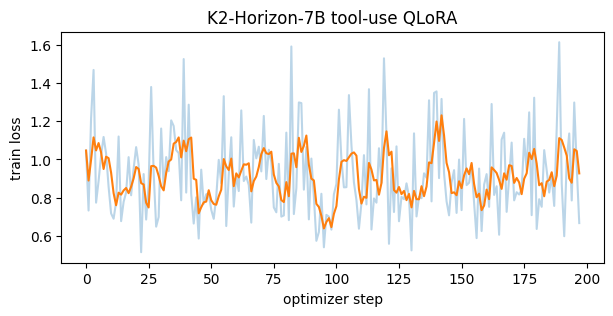

In [10]:
cfg = k2ft.TrainConfig(lr=LR, warmup_ratio=WARMUP_RATIO, grad_accum=GRAD_ACCUM, save_every=SAVE_EVERY_STEPS,
                       log_every=5, time_budget_s=TRAIN_HOURS * 3600 * 1.15, seed=SEED)
state = k2ft.train(model, PLAN["train"], PAD_ID, cfg, DTYPE, CKPT_DIR)
REPORT.update(steps_done=state.step, steps_planned=state.total_steps,
              final_train_loss=state.history[-1]["loss"] if state.history else None)
save_report()

try:
    import matplotlib.pyplot as plt
    h = state.history
    k = max(1, len(h) // 50)
    sm = [sum(x["loss"] for x in h[max(0, i - k):i + 1]) / len(h[max(0, i - k):i + 1]) for i in range(len(h))]
    plt.figure(figsize=(7, 3)); plt.plot([x["loss"] for x in h], alpha=.3); plt.plot(sm)
    plt.xlabel("optimizer step"); plt.ylabel("train loss"); plt.title("K2-Horizon-7B tool-use QLoRA"); plt.show()
except Exception as e:
    print("plot skipped:", e)


## 11 · Save adapter + evaluate (base vs tuned)
* **Eval loss** on held-out Toucan trajectories (teacher-forced).
* **Tool-call accuracy**: from the first user turn, does the model emit the right tool, the right argument keys, and exact values? Run for the tuned model and with the adapter disabled (= base).

In [11]:
model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
print("adapter saved:", ADAPTER_DIR, sorted(p.name for p in ADAPTER_DIR.iterdir()))

REPORT["tuned_eval_loss"] = k2ft.evaluate_loss(model, PLAN["eval"], PAD_ID, DTYPE)
print(f"eval loss  base {REPORT.get('base_eval_loss')}  ->  tuned {REPORT['tuned_eval_loss']:.4f}")

def gen_eval(m, n):
    cases = []
    for s in PLAN["eval"]:
        split = k2ft.first_assistant_call_prefix(s["example"])
        if split:
            cases.append((split[0], s["example"]["tools"], split[1]))
        if len(cases) == n:
            break
    stops = ["</ifm|tool_calls>", "<|ifm|im_end|>"]
    def run():
        scores, samples = [], []
        for ctx, tools, gold in cases:
            prompt = tokenizer.apply_chat_template(ctx, tools=tools, tokenize=False, add_generation_prompt=True,
                                                   reasoning_effort=GEN_EVAL_EFFORT, **CHAT_KWARGS)
            ids = tokenizer(prompt, add_special_tokens=False, return_tensors="pt").to("cuda")
            with torch.no_grad(), torch.autocast("cuda", dtype=DTYPE):
                out = m.generate(**ids, max_new_tokens=1024, do_sample=False, use_cache=True,
                                     stop_strings=stops, tokenizer=tokenizer, pad_token_id=PAD_ID)
            text = tokenizer.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=False)
            pred = k2ft.parse_tool_calls(text)
            scores.append(k2ft.score_first_call(pred, gold))
            samples.append({"gold": gold, "pred": pred, "raw_tail": text[-300:]})
        agg = {k: sum(s[k] for s in scores) / max(1, len(scores)) for k in ("name", "keys", "exact")}
        return agg, samples
    m.eval()
    m.config.use_cache = True
    tuned, tuned_samples = run()
    with m.disable_adapter():
        base, _ = run()
    m.config.use_cache = False
    return base, tuned, tuned_samples

if GEN_EVAL_SAMPLES:
    base_acc, tuned_acc, examples = gen_eval(model, GEN_EVAL_SAMPLES)
    REPORT.update(gen_eval_base=base_acc, gen_eval_tuned=tuned_acc)
    print("tool-call accuracy (first call) — base :", base_acc)
    print("tool-call accuracy (first call) — tuned:", tuned_acc)
    for e in examples[:2]:
        print("\ngold:", e["gold"], "\npred:", e["pred"])
save_report()


adapter saved: /content/drive/MyDrive/k2-horizon-toolft/k2h7b-tooluse-v1/adapter ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json']
eval loss  base 1.055114511971487  ->  tuned 0.8956


[transformers] The remote code model you are currently using seems to expect `cache_position`. This arg has been removed from the Transformers library, and will stop being created in `generate` even for remote code models in a future release. Please open a PR on the remote code hub repo to remove any usage of `cache_position`.


tool-call accuracy (first call) — base : {'name': 1.0, 'keys': 0.875, 'exact': 0.75}
tool-call accuracy (first call) — tuned: {'name': 0.875, 'keys': 0.625, 'exact': 0.625}

gold: [{'name': 'mcpollinations-multimodal-server-listImageModels', 'arguments': {}}] 
pred: [{'name': 'mcpollinations-multimodal-server-listImageModels', 'arguments': {}}]

gold: [{'name': 'flux-imagegen-server-generateImageUrl', 'arguments': {'prompt': 'the Colosseum illuminated by a sunset glow', 'model': 'flux-schnell'}}] 
pred: [{'name': 'flux-imagegen-server-generateImageUrl', 'arguments': {'prompt': 'The Colosseum illuminated by a sunset glow, ancient Roman amphitheater with warm golden light casting long shadows, dramatic sky with orange and pink hues, historical architecture, cinematic lighting, high detail, photorealistic'}}]


## 12 · Merge LoRA into the bf16 base (streaming, CPU)
The adapter is merged **shard by shard** into the original bf16 safetensors (peak RAM ≈ one shard, ~4.5 GB) — a normal `merge_and_unload()` would need the full 18 GB model in RAM. GPU memory is released first.

In [12]:
del model
gc.collect(); torch.cuda.empty_cache()
MERGED_DIR = WORK / "merged"
if EXPORT_GGUF:
    need = 18e9 * 2.3
    if k2ft.free_disk("/content") < need:
        raise SystemExit(f"Need ~{need / 1e9:.0f} GB free on local disk for merge+GGUF, have "
                         f"{k2ft.free_disk('/content') / 1e9:.0f} GB. Delete /content/work or the HF dataset cache.")
    if not (MERGED_DIR / "config.json").exists() or len(list(MERGED_DIR.glob("*.safetensors"))) == 0:
        t = time.time()
        info = k2ft.merge_lora_streaming(BASE_DIR, ADAPTER_DIR, MERGED_DIR)
        print(f"✅ merged {info['merged_modules']} modules (scale {info['scale']}) in {(time.time() - t) / 60:.1f} min")
    shutil.rmtree(Path.home() / ".cache/huggingface/datasets", ignore_errors=True)   # free ~GBs of dataset cache
    print("free disk:", k2ft.human_bytes(k2ft.free_disk("/content")))


[merge] model-00001-of-00036.safetensors: done (7 modules merged so far)
[merge] model-00002-of-00036.safetensors: done (14 modules merged so far)
[merge] model-00003-of-00036.safetensors: done (21 modules merged so far)
[merge] model-00004-of-00036.safetensors: done (28 modules merged so far)
[merge] model-00005-of-00036.safetensors: done (35 modules merged so far)
[merge] model-00006-of-00036.safetensors: done (42 modules merged so far)
[merge] model-00007-of-00036.safetensors: done (49 modules merged so far)
[merge] model-00008-of-00036.safetensors: done (56 modules merged so far)
[merge] model-00009-of-00036.safetensors: done (63 modules merged so far)
[merge] model-00010-of-00036.safetensors: done (70 modules merged so far)
[merge] model-00011-of-00036.safetensors: done (77 modules merged so far)
[merge] model-00012-of-00036.safetensors: done (84 modules merged so far)
[merge] model-00013-of-00036.safetensors: done (91 modules merged so far)
[merge] model-00014-of-00036.safetensor

## 13 · GGUF via the K2Horizon llama.cpp fork
Clones `model/K2Horizon`, builds a CPU `llama-quantize` (fast), converts the merged model to BF16 GGUF with the fork's converter, then quantizes. The fork's converter is used **without** its `requirements.txt` (that file pins a CPU torch which would clobber Colab's CUDA torch); missing pure-python deps are installed on demand.

In [14]:
LLAMA = Path("/content/llama.cpp")
GGUF_DIR = WORK / "gguf"
GGUF_DIR.mkdir(parents=True, exist_ok=True)
STEM = "K2-Horizon-7B-ToolUse"
gguf_files = {}

def clone_fork():
    if (LLAMA / "convert_hf_to_gguf.py").exists():
        return
    for url in LLAMA_CPP_REPOS:
        try:
            sh(f"git clone --depth 1 -b {LLAMA_CPP_BRANCH} {url} {LLAMA}")
            return
        except RuntimeError:
            shutil.rmtree(LLAMA, ignore_errors=True)
    raise RuntimeError("could not clone the K2Horizon llama.cpp fork from any of LLAMA_CPP_REPOS")

def run_py(script, args):
    env = {**os.environ, "PYTHONPATH": f"{LLAMA / 'gguf-py'}:{os.environ.get('PYTHONPATH', '')}"}
    for _ in range(4):
        try:
            return sh(f"{sys.executable} {LLAMA / script} {args}", env=env)
        except RuntimeError as e:
            m = re.search(r"No module named '([\w\.]+)'", str(e))
            if not m:
                raise
            mod = m.group(1).split(".")[0]
            pkg = {"yaml": "pyyaml", "google": "protobuf", "sentencepiece": "sentencepiece"}.get(mod, mod.replace("_", "-"))
            print(f"installing missing dependency: {pkg}")
            sh(f"{sys.executable} -m pip install -q {pkg}")
    raise RuntimeError(f"{script} keeps failing on imports")

if EXPORT_GGUF:
    clone_fork()
    sh(f"git -C {LLAMA} log -1 --format='fork commit %h %cd'")
    if not (LLAMA / "build-cpu/bin/llama-quantize").exists():
        sh(f"cmake -S {LLAMA} -B {LLAMA}/build-cpu -DCMAKE_BUILD_TYPE=Release -DGGML_CUDA=OFF -DLLAMA_CURL=OFF -DLLAMA_BUILD_TESTS=OFF")
        sh(f"cmake --build {LLAMA}/build-cpu -j{os.cpu_count()} --target llama-quantize")
    bf16 = GGUF_DIR / f"{STEM}-BF16.gguf"
    if not bf16.exists():
        run_py("convert_hf_to_gguf.py", f"{MERGED_DIR} --outfile {bf16} --outtype bf16")
    for q in GGUF_QUANTS:
        out = GGUF_DIR / f"{STEM}-{q}.gguf"
        if not out.exists():
            sh(f"{LLAMA}/build-cpu/bin/llama-quantize {bf16} {out} {q} {os.cpu_count()}")
        gguf_files[q] = out
    if KEEP_BF16_GGUF:
        gguf_files["BF16"] = bf16
    if EXPORT_LORA_GGUF:
        lora = GGUF_DIR / f"{STEM}-LoRA-F16.gguf"
        try:
            if not lora.exists():
                run_py("convert_lora_to_gguf.py", f"{ADAPTER_DIR} --base {BASE_DIR} --outfile {lora} --outtype f16")
            gguf_files["LoRA-F16"] = lora
        except Exception as e:
            print("LoRA GGUF export skipped (merged GGUF is unaffected):", str(e)[-500:])
    for k, v in gguf_files.items():
        print(f"{k:>9}: {v}  ({k2ft.human_bytes(v.stat().st_size)})")
    REPORT["gguf"] = {k: v.name for k, v in gguf_files.items()}
    save_report()


$ git -C /content/llama.cpp log -1 --format='fork commit %h %cd'
fork commit 42adf01 Thu Sep 17 17:12:32 2026 +0400
$ /usr/bin/python3 /content/llama.cpp/convert_lora_to_gguf.py /content/drive/MyDrive/k2-horizon-toolft/k2h7b-tooluse-v1/adapter --base /root/.cache/huggingface/hub/models--IFM--K2-Horizon-7B/snapshots/3b6ae394c1b863c27a306d168b25555837955192 --outfile /content/work/gguf/K2-Horizon-7B-ToolUse-LoRA-F16.gguf --outtype f16
INFO:lora-to-gguf:Loading base model: 3b6ae394c1b863c27a306d168b25555837955192
 You can inspect the repository content at https://hf.co//root/.cache/huggingface/hub/models--IFM--K2-Horizon-7B/snapshots/3b6ae394c1b863c27a306d168b25555837955192.
Please pass the argument `trust_remote_code=True` to allow custom code to be run.
INFO:lora-to-gguf:Using model architecture: K2HorizonForCausalLM
INFO:hf-to-gguf:gguf: loading model weight map from 'model.safetensors.index.json'
INFO:hf-to-gguf:gguf: indexing model part 'model-00001-of-00036.safetensors'
INFO:hf-to-g

## 14 · Smoke test: `llama-server --jinja` + a real tool call
Builds a CUDA `llama-server` from the fork for this GPU, loads the quantized GGUF and sends an **OpenAI-style** `/v1/chat/completions` request with Playwright-MCP-style browser tools — the same wire format OpenCode/Harness use. Passing means: the fork loads the file, the embedded chat template renders tools, and the server's K2 parser returns structured `tool_calls`.

In [15]:
import subprocess
subprocess.run("pkill -f llama-quantize", shell=True)          # orphaned process from the crash
for f in GGUF_DIR.glob("*Q4_K_M*.gguf"):                        # partial file would be mistaken as done
    f.unlink(); print("removed partial:", f.name)

def sh(cmd, check=True, cwd=None, env=None):
    print(f"$ {cmd}")
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, encoding="utf-8", errors="replace", bufsize=1)
    lines = []
    for line in p.stdout:
        print(line, end=""); lines.append(line)
    p.wait()
    if check and p.returncode != 0:
        raise RuntimeError(f"command failed ({p.returncode}): {cmd}\n" + "".join(lines[-30:]))
    return "".join(lines)
print("sh() patched")

removed partial: K2-Horizon-7B-ToolUse-Q4_K_M.gguf
sh() patched


In [ ]:
import urllib.request

def http_json(url, payload=None, timeout=600):
    data = json.dumps(payload).encode() if payload is not None else None
    req = urllib.request.Request(url, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return json.loads(r.read().decode())

SERVER_FLAGS = ""
if EXPORT_GGUF and RUN_SERVER_SMOKE_TEST and gguf_files:
    arch = f"{CC[0]}{CC[1]}"
    if not (LLAMA / "build-cuda/bin/llama-server").exists():
        sh(f"cmake -S {LLAMA} -B {LLAMA}/build-cuda -DCMAKE_BUILD_TYPE=Release -DGGML_CUDA=ON "
           f"-DCMAKE_CUDA_ARCHITECTURES={arch} -DLLAMA_CURL=OFF -DLLAMA_BUILD_TESTS=OFF")
        sh(f"cmake --build {LLAMA}/build-cuda -j{os.cpu_count()} --target llama-server")
    help_txt = subprocess.run(f"{LLAMA}/build-cuda/bin/llama-server --help", shell=True,
                              capture_output=True, text=True).stdout
    HAS_TPL_KWARGS = "--chat-template-kwargs" in help_txt
    gguf = gguf_files[GGUF_QUANTS[0]]
    log = open(WORK / "llama-server.log", "w")
    srv = subprocess.Popen([f"{LLAMA}/build-cuda/bin/llama-server", "-m", str(gguf), "--jinja", "-ngl", "99",
                            "-c", "16384", "--host", "127.0.0.1", "--port", "8080", "--alias", SERVED_MODEL_NAME],
                           stdout=log, stderr=subprocess.STDOUT)
    try:
        for _ in range(300):
            try:
                if http_json("http://127.0.0.1:8080/health", timeout=5).get("status") == "ok":
                    break
            except Exception:
                pass
            if srv.poll() is not None:
                raise RuntimeError("llama-server exited:\n" + (WORK / "llama-server.log").read_text()[-3000:])
            time.sleep(2)
        tools = [
            {"type": "function", "function": {"name": "playwright_browser_navigate", "description": "Navigate the browser to a URL",
             "parameters": {"type": "object", "properties": {"url": {"type": "string", "description": "URL to open"}}, "required": ["url"]}}},
            {"type": "function", "function": {"name": "playwright_browser_snapshot", "description": "Capture an accessibility snapshot of the current page",
             "parameters": {"type": "object", "properties": {}}}},
        ]
        req = {"model": SERVED_MODEL_NAME, "temperature": 0.6, "max_tokens": 2048, "tools": tools,
               "messages": [{"role": "system", "content": k2ft.AGENT_SYSTEM_PROMPTS[1]},
                            {"role": "user", "content": "Open https://example.com and tell me the main heading on the page."}],
               "chat_template_kwargs": {"reasoning_effort": "low"}}
        t = time.time()
        resp = http_json("http://127.0.0.1:8080/v1/chat/completions", req)
        msg = resp["choices"][0]["message"]
        calls = msg.get("tool_calls") or []
        print(f"latency {time.time() - t:.1f}s | finish_reason={resp['choices'][0].get('finish_reason')}")
        print("reasoning:", (msg.get("reasoning_content") or "")[:300])
        print("tool_calls:", json.dumps(calls, indent=1))
        ok = bool(calls) and calls[0]["function"]["name"] == "playwright_browser_navigate" \
            and "example.com" in calls[0]["function"]["arguments"]
        REPORT["server_smoke_test"] = "pass" if ok else "fail"
        print("✅ llama-server returned a structured browser tool call" if ok else
              "❌ no structured tool call — see message above and /content/work/llama-server.log")
    finally:
        srv.terminate(); srv.wait(timeout=30); log.close()
    SERVER_FLAGS = "--chat-template-kwargs '{\"reasoning_effort\":\"medium\"}'" if HAS_TPL_KWARGS else ""
    save_report()


$ cmake -S /content/llama.cpp -B /content/llama.cpp/build-cuda -DCMAKE_BUILD_TYPE=Release -DGGML_CUDA=ON -DCMAKE_CUDA_ARCHITECTURES=75 -DLLAMA_CURL=OFF -DLLAMA_BUILD_TESTS=OFF
-- The C compiler identification is GNU 13.3.0
-- The CXX compiler identification is GNU 13.3.0
-- Detecting C compiler ABI info
-- Detecting C compiler ABI info - done
-- Check for working C compiler: /usr/bin/cc - skipped
-- Detecting C compile features
-- Detecting C compile features - done
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/c++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- llama.cpp version: 0.3.0-dev
CMAKE_BUILD_TYPE=Release
-- Found Git: /usr/bin/git (found version "2.43.0")
-- The ASM compiler identification is GNU
-- Found assembler: /usr/bin/cc
-- Performing Test CMAKE_HAVE_LIBC_PTHREAD
-- Performing Test CMAKE_HAVE_LIBC_PTHREAD - Success
-- Found Threads: TRUE
-- Warning: ccach

## 15 · Publish: Hugging Face + Drive + deploy kit
Uploads the adapter, GGUF(s), a model card and a ready-to-use **deploy kit** (`run_server.sh`, `opencode.json`) — the same kit is copied to Drive.

In [ ]:
DEPLOY = RUN_DIR / "deploy"
DEPLOY.mkdir(exist_ok=True)
q0 = GGUF_QUANTS[0]
(DEPLOY / "run_server.sh").write_text(f"""#!/usr/bin/env bash
# K2-Horizon-7B-ToolUse on one 11 GB GPU (e.g. GTX 1080 Ti). Build the K2Horizon fork first:
#   git clone -b {LLAMA_CPP_BRANCH} {LLAMA_CPP_REPOS[0]} && cd llama.cpp
#   cmake -B build -DGGML_CUDA=ON -DCMAKE_CUDA_ARCHITECTURES=61 && cmake --build build -j --target llama-server
set -euo pipefail
LLAMA_DIR=${{LLAMA_DIR:-./llama.cpp}}
MODEL=${{MODEL:-./{STEM}-{q0}.gguf}}
CTX=${{CTX:-32768}}   # 32k fits 11 GB with q8_0 KV cache; OpenCode's system prompt + tools need ~10-15k
exec "$LLAMA_DIR/build/bin/llama-server" -m "$MODEL" --jinja -ngl 99 -c "$CTX" \\
  -fa on -ctk q8_0 -ctv q8_0 --host 127.0.0.1 --port 8080 --alias {SERVED_MODEL_NAME} {SERVER_FLAGS}
""")
opencode_cfg = {
    "$schema": "https://opencode.ai/config.json",
    "provider": {"k2-local": {
        "npm": "@ai-sdk/openai-compatible", "name": "K2-Horizon (llama-server)",
        "options": {"baseURL": "http://127.0.0.1:8080/v1"},
        "models": {SERVED_MODEL_NAME: {"name": "K2-Horizon-7B ToolUse (local)",
                                       "limit": {"context": 32768, "output": 16384}}}}},
    "model": f"k2-local/{SERVED_MODEL_NAME}",
    "small_model": f"k2-local/{SERVED_MODEL_NAME}",
    "mcp": {"playwright": {"type": "local", "command": ["npx", "-y", "@playwright/mcp@latest"], "enabled": True}},
}
(DEPLOY / "opencode.json").write_text(json.dumps(opencode_cfg, indent=2))

card = f"""---
base_model: {BASE_MODEL}
license: apache-2.0
datasets: [{DATASET}]
tags: [k2-horizon, tool-use, function-calling, browser-agent, qlora, gguf]
---
# K2-Horizon-7B-ToolUse ({RUN_NAME})

QLoRA (r={LORA_R}, alpha={LORA_ALPHA}, all linear layers) on {REPORT.get('train_samples')} Toucan-1.5M SFT trajectories
({int(WEB_FRACTION * 100)}% browser/web), seq {MAX_SEQ_LEN}, lr {LR}, 1 epoch, trained on a Colab T4.
Assistant turns only; reasoning blocks masked (the data has none), so native thinking is preserved.

| metric | base | tuned |
|---|---|---|
| held-out eval loss | {REPORT.get('base_eval_loss')} | {REPORT.get('tuned_eval_loss')} |
| first-call tool name acc | {REPORT.get('gen_eval_base', {}).get('name')} | {REPORT.get('gen_eval_tuned', {}).get('name')} |
| first-call exact args | {REPORT.get('gen_eval_base', {}).get('exact')} | {REPORT.get('gen_eval_tuned', {}).get('exact')} |

llama-server smoke test: **{REPORT.get('server_smoke_test', 'not run')}**

**GGUF requires the K2Horizon llama.cpp fork** (`{LLAMA_CPP_REPOS[0]}`, branch `{LLAMA_CPP_BRANCH}`) — upstream llama.cpp cannot load `k2-horizon` yet.
Serve with `--jinja` so the embedded K2 chat template and tool-call parser are used. See `deploy/` for `run_server.sh` and `opencode.json`.
"""
(RUN_DIR / "README.md").write_text(card)
print(card)

if USE_DRIVE and IN_COLAB:
    gdir = RUN_DIR / "gguf"
    gdir.mkdir(exist_ok=True)
    for k, f in gguf_files.items():
        if k != "BF16" and not (gdir / f.name).exists():
            print("copying to Drive:", f.name); shutil.copy2(f, gdir / f.name)

if HF_PUSH and HF_TOKEN:
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    repo = HF_REPO_ID or f"{api.whoami()['name']}/K2-Horizon-7B-ToolUse"
    api.create_repo(repo, private=HF_PRIVATE, exist_ok=True)
    api.upload_folder(repo_id=repo, folder_path=str(ADAPTER_DIR), path_in_repo="adapter")
    api.upload_folder(repo_id=repo, folder_path=str(DEPLOY), path_in_repo="deploy")
    api.upload_file(repo_id=repo, path_or_fileobj=str(RUN_DIR / "README.md"), path_in_repo="README.md")
    api.upload_file(repo_id=repo, path_or_fileobj=str(REPORT_PATH), path_in_repo="report.json")
    for f in gguf_files.values():
        print("uploading", f.name)
        api.upload_file(repo_id=repo, path_or_fileobj=str(f), path_in_repo=f.name)
    REPORT["hf_repo"] = repo
    save_report()
    print(f"✅ https://huggingface.co/{repo}")
elif HF_PUSH:
    print("HF upload skipped (no HF_TOKEN). Artifacts are on Drive:", RUN_DIR)
print(json.dumps(REPORT, indent=2))


## 16 · Run it on your PC with OpenCode / Harness

1. **Build the fork** with CUDA for your GPU (`61` = GTX 1080 Ti, `86` = RTX 30xx, `89` = RTX 40xx):
   ```bash
   git clone -b model/K2Horizon https://github.com/MBZUAI-IFM/llama.cpp && cd llama.cpp
   cmake -B build -DGGML_CUDA=ON -DCMAKE_CUDA_ARCHITECTURES=61 && cmake --build build -j --target llama-server
   ```
2. **Download** `K2-Horizon-7B-ToolUse-Q4_K_M.gguf` + `deploy/` from your HF repo (or Drive) and run `bash deploy/run_server.sh`.
3. **Point OpenCode/Harness at it**: copy `deploy/opencode.json` to `~/.config/opencode/opencode.json` (or your project root). It registers the local model and the **Playwright MCP** browser server (`npx @playwright/mcp`). Then `/models` → *K2-Horizon-7B ToolUse (local)*.

Sanity check without the harness:
```bash
curl -s http://127.0.0.1:8080/v1/chat/completions -H 'Content-Type: application/json' -d '{
  "model":"k2-horizon-7b-tooluse","max_tokens":2048,
  "tools":[{"type":"function","function":{"name":"browser_navigate","description":"Open a URL",
    "parameters":{"type":"object","properties":{"url":{"type":"string"}},"required":["url"]}}}],
  "messages":[{"role":"user","content":"Open https://example.com"}]}' | jq '.choices[0].message.tool_calls'
```
